              Gene1      Gene2      Gene3      Gene4      Gene5    Group
GSM15965  17.224840  17.067668  16.969759  16.874140  16.674505  Control
GSM15966  15.876169  14.965234  16.231232  15.656092  15.281039  Control
GSM15967  10.976994  12.921636  15.084846  14.307101  14.081525  Control
GSM15968  18.569110  17.245236  17.592448  16.898117  16.384710  Disease
GSM15969  16.475745  16.364490  17.113781  16.592204  15.767062  Disease
GSM15970  16.037118  16.599233  17.006380  16.974075  14.906031  Disease

=== 分组均值计算结果 ===
             Gene1      Gene2      Gene3      Gene4      Gene5
Group                                                         
Control  14.692668  14.984846  16.095279  15.612444  15.345690
Disease  17.027324  16.736320  17.237536  16.821466  15.685934


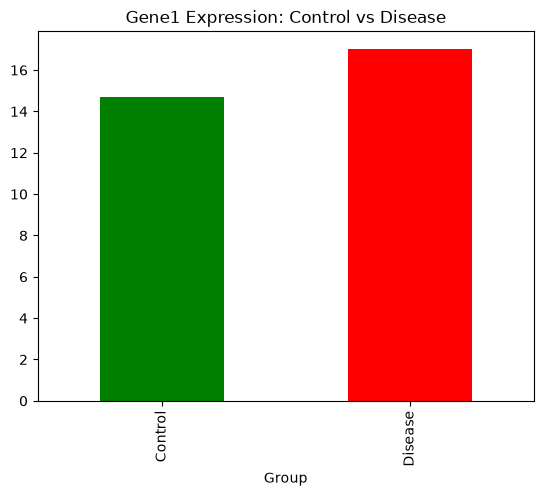

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # 画图的工具包

# 1. 召唤昨天的数据
df = pd.read_csv('GSE1009_log2_sorted.csv')

# 2. 核心操作：给样本分组
# 手动定义这6个样本的属性（假设前3个是Control，后3个是Disease）
sample_names = ['GSM15965', 'GSM15966', 'GSM15967', 'GSM15968', 'GSM15969', 'GSM15970']
groups = ['Control', 'Control', 'Control', 'Disease', 'Disease', 'Disease']

# 3. 提取要研究的基因
# 取前5行基因的数据来练手
subset = df.iloc[:5, :6] # 取前5行，前6列数字（剔除ID列）

# 4. 转置数据（行列互换，让样本变成行，基因变成列，方便画图）
subset_T = subset.T
subset_T.columns = ['Gene1', 'Gene2', 'Gene3', 'Gene4', 'Gene5'] # 随便给前5个基因起个名
subset_T['Group'] = groups # 把刚才定义的分组加进去

print(subset_T) # 先看一眼转置后的表格长什么样

# 5. 分组计算均值
group_mean = subset_T.groupby('Group').mean()
print("\n=== 分组均值计算结果 ===")
print(group_mean)

# 6. 可视化：画一个简单的柱状图，看Gene1在两组里的差异
group_mean['Gene1'].plot(kind='bar', color=['green', 'red'], title='Gene1 Expression: Control vs Disease')
plt.show()
# 把图显示出来